# 🎓 Bài 1: Huấn luyện mô hình AI đầu tiên

**Buổi 3: Máy học hoạt động như thế nào?** · ⏱️ 25 phút

Sau bài này bạn sẽ:
- Huấn luyện được một mạng nơ-ron nhỏ chỉ với vài dòng code
- Nhìn thấy mô hình "học" dần qua từng epoch
- Giải thích được vì sao mạng nơ-ron cần **hàm kích hoạt phi tuyến** (slide 29)

### Cách làm bài
| Ký hiệu | Ý nghĩa |
|---|---|
| 🔍 **Xem mẫu** | Code đã viết sẵn. Đọc chú thích rồi bấm chạy |
| 🤔 **Dự đoán** | Đoán kết quả **trước khi** chạy, đoán sai vẫn học được nhiều |
| ✏️ **Tự làm** | Thay mọi dấu `____` bằng code của bạn |
| ✅ **Kiểm tra** | Ô tự chấm và gợi ý cách sửa |
| 💬 **Giải thích** | Viết một câu theo cách hiểu của bạn |

**Chạy một ô:** bấm vào ô rồi nhấn `Shift + Enter`. Hãy chạy **từ trên xuống dưới, không bỏ ô nào**.

Bắt đầu bằng ô cài đặt bên dưới. Bạn không cần đọc code trong ô này.

In [1]:
#@title ⚙️ Ô cài đặt: bấm ▶ để chạy, không cần đọc code { display-mode: "form" }

import os, time, unicodedata, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from matplotlib.animation import FuncAnimation
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import HTML, display
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

MAU_TRAIN, MAU_VAL, MAU_3 = "#2a78d6", "#eb6834", "#1baf7a"
MAU_LOP0, MAU_LOP1 = "#e34948", "#2a78d6"
MUC_CHINH, MUC_PHU = "#0b0b0b", "#52514e"
NEN_HAI_LOP = LinearSegmentedColormap.from_list("nen", ["#f3b4b3", "#f0efec", "#a9c9f0"])

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "text.color": MUC_CHINH, "axes.labelcolor": MUC_PHU, "axes.titlecolor": MUC_CHINH,
    "xtick.color": MUC_PHU, "ytick.color": MUC_PHU, "lines.linewidth": 2, "font.size": 11,
    "axes.titlesize": 12, "legend.frameon": False, "figure.dpi": 100, "animation.embed_limit": 40,
})


def _bao_loi_than_thien(self, etype, value, tb, tb_offset=None):
    ten = getattr(value, "name", None) or str(value)
    if "____" in str(value):
        print("✏️  Ô này còn chỗ trống ____ chưa điền.\n"
              "    Hãy thay MỌI dấu ____ trong ô bằng giá trị theo gợi ý, rồi chạy lại ô.")
    else:
        print(f"🔎 Python chưa biết tên `{ten}`. Thường là do một trong ba lý do:\n"
              "    1. Một ô phía trên chưa chạy hoặc còn lỗi: hãy chạy lại các ô từ trên xuống.\n"
              "    2. Gõ sai tên (hoa/thường cũng tính là khác nhau).\n"
              '    3. Quên dấu ngoặc kép với chữ, ví dụ phải viết "relu" chứ không phải relu.')


try:
    get_ipython().set_custom_exc((NameError,), _bao_loi_than_thien)
except Exception:
    pass


def _dung(thong_bao):
    print("✅ " + thong_bao)


def _sai(thong_bao):
    print("❌ " + thong_bao)


def _luoi(X, n=90):
    bien_x = (X[:, 0].max() - X[:, 0].min()) * 0.12
    bien_y = (X[:, 1].max() - X[:, 1].min()) * 0.12
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - bien_x, X[:, 0].max() + bien_x, n),
                         np.linspace(X[:, 1].min() - bien_y, X[:, 1].max() + bien_y, n))
    return xx, yy, np.c_[xx.ravel(), yy.ravel()].astype("float32")


def _xac_suat(model, luoi, hinh_dang):
    return np.array(model(luoi, training=False)).reshape(hinh_dang)


def _ve_nen(ax, xx, yy, zz):
    ax.contourf(xx, yy, zz, levels=np.linspace(0, 1, 41), cmap=NEN_HAI_LOP, vmin=0, vmax=1)
    if zz.min() < 0.5 < zz.max():
        ax.contour(xx, yy, zz, levels=[0.5], colors=MUC_CHINH, linewidths=2)


def _ve_diem(ax, X, y, nhan, rong=False):
    for lop, mau, dau in [(0, MAU_LOP0, "s"), (1, MAU_LOP1, "o")]:
        loc = np.asarray(y) == lop
        ten = f"{nhan[lop]}" + (" (validation)" if rong else "")
        if rong:
            ax.scatter(X[loc, 0], X[loc, 1], s=46, marker=dau, facecolors="#fcfcfb",
                       edgecolors=mau, linewidths=1.6, label=ten, zorder=3)
        else:
            ax.scatter(X[loc, 0], X[loc, 1], s=46, marker=dau, c=mau,
                       edgecolors="#fcfcfb", linewidths=0.8, label=ten, zorder=3)


class GhiLaiRanhGioi(tf.keras.callbacks.Callback):
    """Chụp lại đường phân chia của mô hình sau mỗi vài epoch."""

    def __init__(self, X, moi_bao_nhieu_epoch=2):
        super().__init__()
        self.moi = moi_bao_nhieu_epoch
        self.xx, self.yy, self.luoi = _luoi(X)
        self.cac_epoch, self.cac_khung = [], []

    def _chup(self, epoch):
        self.cac_epoch.append(epoch)
        self.cac_khung.append(_xac_suat(self.model, self.luoi, self.xx.shape))

    def on_train_begin(self, logs=None):
        self._chup(0)

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.moi == 0:
            self._chup(epoch + 1)


def xem_qua_trinh_hoc(ghi_lai, lich_su, X_train, y_train, nhan=("Lớp 0", "Lớp 1"),
                      truc=("x1", "x2"), X_val=None, y_val=None):
    """Hoạt ảnh: bên trái là đường phân chia, bên phải là đường cong loss."""
    train, val = lich_su.history["loss"], lich_su.history["val_loss"]
    so_epoch = np.arange(1, len(train) + 1)
    fig, (ax_trai, ax_phai) = plt.subplots(1, 2, figsize=(10.5, 4.3), dpi=80)
    ax_phai.set_xlim(0, len(train))
    ax_phai.set_ylim(0, max(max(train), max(val)) * 1.08)
    ax_phai.set_xlabel("Epoch (số lần học hết dữ liệu)")
    ax_phai.set_ylabel("Hàm mất mát (loss)")
    duong_train, = ax_phai.plot([], [], color=MAU_TRAIN, label="Train (bài tập)")
    duong_val, = ax_phai.plot([], [], color=MAU_VAL, label="Validation (thi thử)")
    con_tro = ax_phai.axvline(0, color=MUC_PHU, linestyle="--", linewidth=1)
    ax_phai.legend(loc="upper right")
    ax_phai.set_title("Sai số theo thời gian")

    def ve_khung(i):
        epoch = ghi_lai.cac_epoch[i]
        ax_trai.clear()
        _ve_nen(ax_trai, ghi_lai.xx, ghi_lai.yy, ghi_lai.cac_khung[i])
        _ve_diem(ax_trai, X_train, y_train, nhan)
        if X_val is not None:
            _ve_diem(ax_trai, X_val, y_val, nhan, rong=True)
        ax_trai.set_xlim(ghi_lai.xx.min(), ghi_lai.xx.max())
        ax_trai.set_ylim(ghi_lai.yy.min(), ghi_lai.yy.max())
        ax_trai.set_xlabel(truc[0])
        ax_trai.set_ylabel(truc[1])
        ax_trai.grid(False)
        ax_trai.set_title(f"Đường phân chia sau epoch {epoch}")
        ax_trai.legend(loc="best", fontsize=8, frameon=True, framealpha=0.85, edgecolor="none")
        duong_train.set_data(so_epoch[:epoch], train[:epoch])
        duong_val.set_data(so_epoch[:epoch], val[:epoch])
        con_tro.set_xdata([epoch, epoch])

    ve_khung(0)
    fig.tight_layout()
    hoat_anh = FuncAnimation(fig, ve_khung, frames=len(ghi_lai.cac_khung), interval=180)
    html = hoat_anh.to_jshtml(default_mode="once")
    plt.close(fig)
    return HTML(html)


def ve_duong_cong(lich_su, tieu_de=""):
    """Vẽ 2 biểu đồ: loss và accuracy của train + validation."""
    fig, cac_truc = plt.subplots(1, 2, figsize=(10.5, 3.8))
    for ax, khoa, nhan_y in zip(cac_truc, ["loss", "accuracy"], ["Hàm mất mát (loss)", "Độ chính xác (accuracy)"]):
        for ten, tien_to, mau in [("Train", "", MAU_TRAIN), ("Validation", "val_", MAU_VAL)]:
            du_lieu = lich_su.history[tien_to + khoa]
            ax.plot(range(1, len(du_lieu) + 1), du_lieu, color=mau, label=ten)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(nhan_y)
        ax.legend()
    if tieu_de:
        fig.suptitle(tieu_de)
    fig.tight_layout()
    plt.show()



def tao_du_lieu_qua_mon():
    """Dữ liệu giả lập 200 sinh viên cho bài toán ở slide 11."""
    rng = np.random.default_rng(42)
    X = np.c_[rng.uniform(0, 10, 200), rng.uniform(0, 10, 200)]
    y = ((0.5 * X[:, 0] + 0.6 * X[:, 1] + rng.normal(0, 0.4, 200)) > 4).astype("int32")
    return X, y


def ve_du_lieu(X, y, nhan=("Lớp 0", "Lớp 1"), truc=("x1", "x2"), diem=None, tieu_de=""):
    fig, ax = plt.subplots(figsize=(6, 4.4))
    _ve_diem(ax, X, y, nhan)
    if diem is not None:
        ax.scatter(*diem, s=170, marker="*", c="#6250d6", edgecolors="#fcfcfb", zorder=4, label=f"Bạn {list(diem)}: ?")
    ax.set_xlabel(truc[0])
    ax.set_ylabel(truc[1])
    ax.set_title(tieu_de)
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
    fig.tight_layout()
    plt.show()


def du_doan_diem(model, x1, x2, nhan=("Lớp 0", "Lớp 1")):
    """Suy luận: đưa một điểm mới vào mô hình và in dự đoán."""
    p = float(np.array(model(np.array([[x1, x2]], dtype="float32"), training=False)).ravel()[0])
    print(f"Đầu vào [{x1}, {x2}] → mô hình tính ra {p:.2f} → dự đoán: {nhan[int(p >= 0.5)]}")
    return p


def so_sanh_ranh_gioi(model_a, lich_su_a, ten_a, model_b, lich_su_b, ten_b, X, y):
    xx, yy, luoi = _luoi(X)
    fig, cac_truc = plt.subplots(1, 2, figsize=(10.5, 4.3), sharex=True, sharey=True)
    for ax, model, lich_su, ten in zip(cac_truc, [model_a, model_b], [lich_su_a, lich_su_b], [ten_a, ten_b]):
        _ve_nen(ax, xx, yy, _xac_suat(model, luoi, xx.shape))
        _ve_diem(ax, X, y, ("Lớp 0", "Lớp 1"))
        ax.grid(False)
        ax.set_xlim(xx.min(), xx.max())
        ax.set_ylim(yy.min(), yy.max())
        ax.set_xlabel("x1")
        ax.set_title(f"{ten}\nval accuracy = {lich_su.history['val_accuracy'][-1]:.2f}")
    cac_truc[0].set_ylabel("x2")
    cac_truc[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
    fig.tight_layout()
    plt.show()


def _lop_dense(model):
    return [l for l in model.layers if isinstance(l, tf.keras.layers.Dense)]


def _da_huan_luyen(model):
    return int(np.array(model.optimizer.iterations)) > 0


def kiem_tra_chia_du_lieu(X_train, X_val):
    if len(X_train) == 210 and len(X_val) == 90:
        _dung(f"Train có {len(X_train)} điểm, validation có {len(X_val)} điểm. Chia đúng tỉ lệ 70/30!")
    else:
        _sai(f"Đang có train = {len(X_train)}, validation = {len(X_val)}. Hãy dùng X2, y2 và test_size=0.3.")


def _kiem_tra_mo_hinh(model, lich_su, ham_mong_doi):
    tot = True
    lop = _lop_dense(model)
    if model.input_shape[-1] != 2:
        _sai("Input cần shape=(2,) vì mỗi điểm có 2 đặc trưng là x1 và x2."); tot = False
    if lop[-1].activation.__name__ != "sigmoid" or lop[-1].units != 1:
        _sai('Lớp cuối cần Dense(1, activation="sigmoid") để cho ra một xác suất từ 0 đến 1.'); tot = False
    an = {l.activation.__name__ for l in lop[:-1]}
    if an != {ham_mong_doi}:
        _sai(f'Các lớp ẩn cần activation="{ham_mong_doi}", hiện đang là {sorted(an)}.'); tot = False
    if not _da_huan_luyen(model):
        _sai("Mô hình chưa được huấn luyện: hãy kiểm tra dòng .fit(...)."); tot = False
    if "val_loss" not in lich_su.history:
        _sai("fit() chưa có validation_data, nên chưa có đường cong validation."); tot = False
    if tot:
        _dung(f"Mô hình đúng cấu trúc. Val accuracy = {lich_su.history['val_accuracy'][-1]:.2f}")


def kiem_tra_mo_hinh_thang(model, lich_su):
    _kiem_tra_mo_hinh(model, lich_su, "linear")


def kiem_tra_mo_hinh_cong(model, lich_su):
    _kiem_tra_mo_hinh(model, lich_su, "relu")


print("✅ Cài đặt xong! TensorFlow phiên bản", tf.__version__)

✅ Cài đặt xong! TensorFlow phiên bản 2.17.0


---
# 🔍 Phần A: Xem mẫu (10 phút)

## A1. Bài toán: Tôi có qua môn được không?

Đây là ví dụ ở **slide 11**. Với mỗi sinh viên ta biết:

| Thuật ngữ | Trong bài này | Trong code |
|---|---|---|
| **Đặc trưng** (đầu vào) | x1 = số buổi đi học, x2 = số giờ làm đồ án | `X` |
| **Nhãn** (đáp án thật) | 1 = Đậu, 0 = Trượt | `y` |
| **Dự đoán** | Con số mô hình tính ra | Có sau khi gọi mô hình |

> ⭐ Câu hỏi của chúng ta: một bạn đi học **4 buổi** và làm đồ án **5 giờ** thì có qua môn không?
>
> Dữ liệu bài này là **giả lập** để minh họa, không phải điểm số thật.

Số sinh viên và số đặc trưng: (200, 2)
3 sinh viên đầu tiên  [x1, x2]: [[7.7, 7.8], [4.4, 9.7], [8.6, 5.0]]
Nhãn của 3 bạn đó (1 = Đậu):    [1, 1, 1]


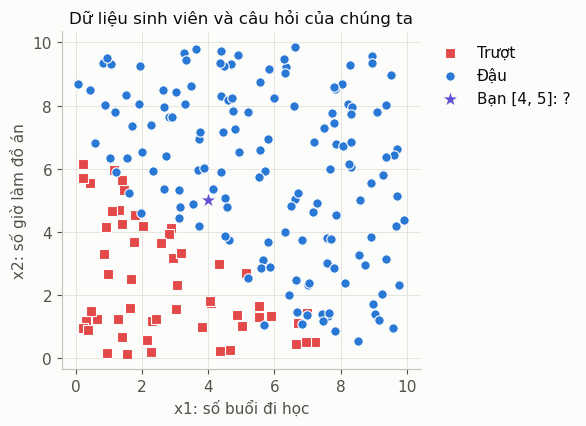

In [2]:
X, y = tao_du_lieu_qua_mon()   # X: đặc trưng, y: nhãn

print("Số sinh viên và số đặc trưng:", X.shape)   # (200, 2) nghĩa là 200 dòng, 2 cột
print("3 sinh viên đầu tiên  [x1, x2]:", X[:3].round(1).tolist())
print("Nhãn của 3 bạn đó (1 = Đậu):   ", y[:3].tolist())

ve_du_lieu(X, y, nhan=("Trượt", "Đậu"), truc=("x1: số buổi đi học", "x2: số giờ làm đồ án"),
           diem=[4, 5], tieu_de="Dữ liệu sinh viên và câu hỏi của chúng ta")

## A2. Chia dữ liệu: "bài tập" và "đề thi thử"

Muốn biết học sinh hiểu bài thật hay chỉ thuộc lòng, ta phải kiểm tra bằng **đề chưa từng thấy**. Vì vậy ta chia dữ liệu làm hai phần:

- **Tập train** (bài tập): mô hình được học từ phần này
- **Tập validation** (đề thi thử): mô hình **không** được học, chỉ dùng để đo xem nó làm tốt thế nào

| Tham số của `train_test_split` | Ý nghĩa |
|---|---|
| `X, y` | Dữ liệu cần chia |
| `test_size=0.25` | Để riêng 25% làm validation |
| `random_state=42` | Cố định cách chia để cả lớp có cùng kết quả. Số nào cũng được |

In [3]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, random_state=42)

print("Train (bài tập):         ", len(X_train), "sinh viên")
print("Validation (đề thi thử): ", len(X_val), "sinh viên")

Train (bài tập):          150 sinh viên
Validation (đề thi thử):  50 sinh viên


## A3. Tạo mô hình

Ta dựng đúng mạng ở **slide 12**: 2 đầu vào → 3 nơ-ron ẩn (z1, z2, z3) → 1 đầu ra.

```
x1 ─┐   ┌─ z1 ─┐
    ├───┼─ z2 ─┼──▶ ŷ   (xác suất đậu)
x2 ─┘   └─ z3 ─┘
```

| Code | Ý nghĩa |
|---|---|
| `tf.keras.Sequential([...])` | Xếp các lớp nối tiếp nhau như xếp hình |
| `Input(shape=(2,))` | Mỗi đầu vào có **2** con số (x1, x2) |
| `Dense(3, activation="relu")` | Lớp có **3** nơ-ron, dùng hàm kích hoạt ReLU (slide 28) |
| `Dense(1, activation="sigmoid")` | Lớp ra có **1** nơ-ron. Sigmoid ép kết quả về khoảng 0 đến 1, đọc như xác suất |

`set_random_seed(42)` cố định các trọng số ngẫu nhiên ban đầu (bước 1 của Gradient Descent, slide 23).

## A4. 🤔 Mô hình chưa học thì đoán thế nào?

**Dự đoán trước khi chạy:** con số tính ra cho bạn `[4, 5]` sẽ có ý nghĩa gì không?

In [4]:
tf.keras.utils.set_random_seed(7)   # cố định trọng số ngẫu nhiên ban đầu

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),                 # đầu vào: 2 đặc trưng
    tf.keras.layers.Dense(3, activation="relu"),       # lớp ẩn: 3 nơ-ron
    tf.keras.layers.Dense(1, activation="sigmoid"),    # đầu ra: xác suất đậu
])

print("Số trọng số cần học:", model.count_params())
print("\nMô hình CHƯA học gì:")
ket_qua_truoc = du_doan_diem(model, 4, 5, nhan=("Trượt", "Đậu"))

KeyboardInterrupt: 

Trọng số lúc này hoàn toàn ngẫu nhiên, nên con số trên **chỉ là đoán bừa**, giống ví dụ "Dự đoán: 0.1, Thực tế: 1" ở slide 12.

## A5. Huấn luyện mô hình

**Bước 1: `compile`** cho mô hình biết sẽ học như thế nào:

| Tham số | Giá trị | Ý nghĩa |
|---|---|---|
| `optimizer` | `Adam(learning_rate=0.01)` | Thuật toán "xuống núi" (slide 37–39). `learning_rate` là độ dài mỗi bước chân η |
| `loss` | `"binary_crossentropy"` | Hàm mất mát cho bài toán 2 lớp, đo mức độ dự đoán sai |
| `metrics` | `["accuracy"]` | In thêm tỉ lệ đoán đúng để con người dễ đọc |

**Bước 2: `fit`** bắt đầu học thật:

| Tham số | Giá trị | Ý nghĩa |
|---|---|---|
| `X_train, y_train` | | Dữ liệu để học |
| `validation_data` | `(X_val, y_val)` | Đề thi thử, chấm sau mỗi epoch |
| `epochs` | `60` | Học hết toàn bộ dữ liệu **60 lần** |
| `batch_size` | `16` | Cứ xem 16 sinh viên thì cập nhật trọng số một lần (slide 42) |
| `verbose` | `0` | Không in log cho gọn |
| `callbacks` | `[ghi_lai]` | Công cụ của bài này: chụp lại đường phân chia để làm hoạt ảnh |

> 🔗 **Nối với slide 39:** một dòng `fit()` đã làm giúp ta cả vòng lặp: lấy một lô dữ liệu → dự đoán → tính loss → tính gradient → cập nhật trọng số → lặp lại.

In [ ]:
# Bước 1: cho mô hình biết cách học
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

ghi_lai = GhiLaiRanhGioi(X)   # công cụ chụp ảnh quá trình học

# Bước 2: học!
lich_su = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=60,
    batch_size=16,
    verbose=0,
    callbacks=[ghi_lai],
)

print("Huấn luyện xong!")
print(f"Loss trên đề thi thử:  {lich_su.history['val_loss'][0]:.2f} (epoch đầu) → {lich_su.history['val_loss'][-1]:.2f} (epoch cuối)")
print(f"Độ chính xác đề thi thử: {lich_su.history['val_accuracy'][-1]:.0%}")

Huấn luyện xong!
Loss trên đề thi thử:  0.84 (epoch đầu) → 0.20 (epoch cuối)
Độ chính xác đề thi thử: 90%


## A6. 🎬 Xem mô hình học

Bấm nút ▶ dưới hình để chạy, hoặc kéo thanh trượt để xem từng thời điểm.

- **Bên trái:** vùng đỏ là mô hình đoán Trượt, vùng xanh là Đậu, đường đen là ranh giới 50/50
- **Bên phải:** sai số giảm dần. Đây chính là quá trình **xuống núi** ở slide 17–22

In [ ]:
xem_qua_trinh_hoc(ghi_lai, lich_su, X_train, y_train, nhan=("Trượt", "Đậu"),
                  truc=("x1: số buổi đi học", "x2: số giờ làm đồ án"))

## A7. Suy luận: hỏi mô hình đã học

Đây là phần **Inference** ở slide 9: đưa dữ liệu mới vào và lấy dự đoán. Bước này dùng trọng số đã học và **không cập nhật** trọng số nữa, nên hỏi bao nhiêu lần cũng ra cùng một đáp án.

In [ ]:
print(f"Trước khi học, mô hình tính ra: {ket_qua_truoc:.2f}")
print("Sau khi học:")
du_doan_diem(model, 4, 5, nhan=("Trượt", "Đậu"))

# 👉 Thử đổi số buổi và số giờ của chính bạn rồi chạy lại ô này
du_doan_diem(model, 1, 2, nhan=("Trượt", "Đậu"));

Trước khi học, mô hình tính ra: 0.07
Sau khi học:
Đầu vào [4, 5] → mô hình tính ra 0.87 → dự đoán: Đậu
Đầu vào [1, 2] → mô hình tính ra 0.06 → dự đoán: Trượt


---
# ✏️ Phần B: Bạn tự làm (15 phút)

Bài toán khó hơn: hai nhóm điểm có dạng **trăng khuyết** lồng vào nhau, giống tinh thần slide 29.

## B1. Xem dữ liệu

🤔 **Dự đoán:** nếu chỉ được vẽ **một đường thẳng**, bạn tách được hai nhóm này không?

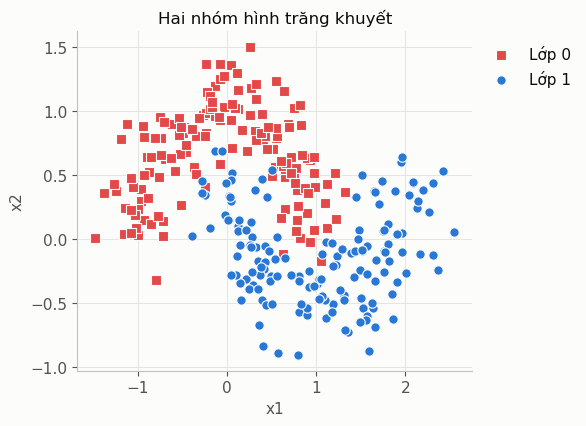

In [6]:
# n_samples: số điểm · noise: độ nhiễu, càng lớn càng lẫn lộn · random_state: cố định kết quả
X2, y2 = make_moons(n_samples=300, noise=0.2, random_state=42)

ve_du_lieu(X2, y2, tieu_de="Hai nhóm hình trăng khuyết")

## B2. ✏️ Chia dữ liệu

Chia theo tỉ lệ **70% train, 30% validation**, làm giống mục A2.

<details><summary>💡 Bấm để xem gợi ý</summary>

Hai chỗ trống đầu là dữ liệu của bài này: `X2` và `y2`. `test_size` là tỉ lệ dành cho validation, viết dưới dạng số thập phân.
</details>

In [8]:
X_train2, X_val2, y_train2, y_val2 = train_test_split(X2,y2, test_size=0.3, random_state=42)

kiem_tra_chia_du_lieu(X_train2, X_val2)

✅ Train có 210 điểm, validation có 90 điểm. Chia đúng tỉ lệ 70/30!


## B3. ✏️ Mô hình 1: hàm kích hoạt tuyến tính

Slide 29 nói: *"Dù mạng có nhiều lớp hay nhiều neuron, biên quyết định vẫn là đường thẳng"*. Hãy tự kiểm chứng bằng một mạng **3 lớp ẩn** dùng `"linear"`.

Điền theo chú thích ở từng dòng. Chữ phải nằm trong dấu ngoặc kép, ví dụ `"linear"`.

<details><summary>💡 Bấm để xem gợi ý</summary>

- `shape=(2,)` vì mỗi điểm có 2 đặc trưng
- Lớp ra của bài toán 2 lớp dùng `"sigmoid"`, xem lại mục A3
- `loss` giống hệt mục A5: `"binary_crossentropy"`
- Đề thi thử của bài này là `(X_val2, y_val2)`
</details>

In [11]:
tf.keras.utils.set_random_seed(42)

model_thang = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),                   # ✏️ mỗi điểm có mấy đặc trưng?
    tf.keras.layers.Dense(16, activation="linear"),
    tf.keras.layers.Dense(1, activation="sigmoid"),        # ✏️ hàm cho ra xác suất từ 0 đến 1
])

model_thang.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss="binary_crossentropy",                            # ✏️ hàm mất mát cho bài toán 2 lớp
    metrics=["accuracy"],
)

lich_su_thang = model_thang.fit(
    X_train2, y_train2,
    validation_data=(X_val2,y_val2),                      # ✏️ đề thi thử
    epochs=60,                                             # ✏️ học 60 lần
    batch_size=16,                                         # ✏️ mỗi lô 16 điểm
    verbose=0,
)

kiem_tra_mo_hinh_thang(model_thang, lich_su_thang)

✅ Mô hình đúng cấu trúc. Val accuracy = 0.89


## B4. ✏️ Mô hình 2: hàm kích hoạt phi tuyến

Bây giờ **chỉ đổi đúng một thứ**: thay `"linear"` bằng `"relu"` ở cả 3 lớp ẩn.

🤔 **Dự đoán:** đường phân chia sẽ thay đổi thế nào?

In [ ]:
tf.keras.utils.set_random_seed(42)

model_cong = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),
    tf.keras.layers.Dense(16, activation="relu"),          # ✏️ hàm phi tuyến
    tf.keras.layers.Dense(16, activation="relu"),          # ✏️
    tf.keras.layers.Dense(16, activation="relu"),          # ✏️

    tf.keras.layers.Dense(1, activation="sigmoid"),
])

model_cong.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

lich_su_cong = model_cong.fit(                             # ✏️ lệnh bắt đầu học
    X_train2, y_train2,
    validation_data=(X_val2, y_val2),
    epochs=60,
    batch_size=16,
    verbose=0,
)

kiem_tra_mo_hinh_cong(model_cong, lich_su_cong)

✅ Mô hình đúng cấu trúc. Val accuracy = 1.00


## B5. So sánh kết quả

Chạy ô dưới đây để đặt hai mô hình cạnh nhau.

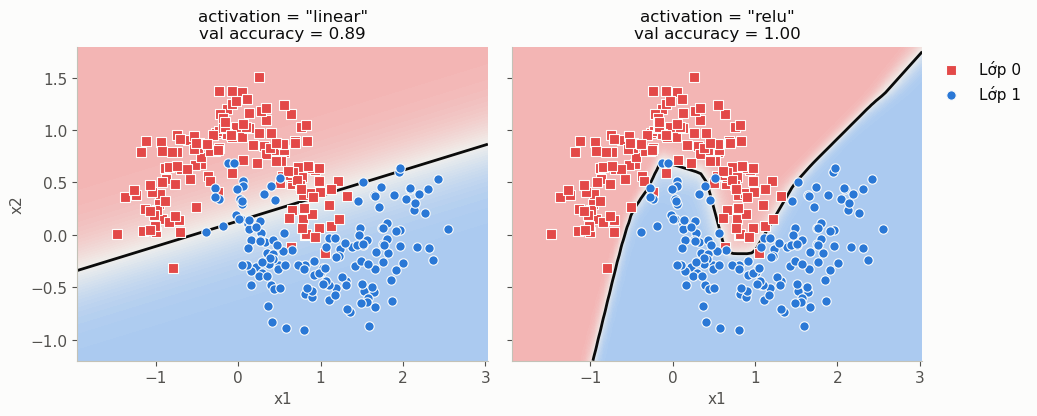

In [14]:
so_sanh_ranh_gioi(model_thang, lich_su_thang, 'activation = "linear"',
                  model_cong, lich_su_cong, 'activation = "relu"', X2, y2)

### 💬 Giải thích bằng lời của bạn

Bấm đúp vào ô này và hoàn thành câu:

> Khi dùng `linear`, đường phân chia có dạng đường thẳng, còn khi dùng `relu` thì có dạng gấp khúc, vì ở các vùng đầu vào khác nhau, các nơ-ron có thể bật hoặc tắt khác nhau, giúp mô hình ghép nhiều đoạn thẳng thành đường phân chia.

<details><summary>💡 Bấm để xem một câu trả lời mẫu</summary>

Khi dùng `linear`, đường phân chia luôn là đường thẳng, vì ghép nhiều phép tính tuyến tính lại vẫn chỉ ra một phép tính tuyến tính, thêm lớp cũng không giúp gì. `relu` có chỗ "gấp khúc", nên nhiều nơ-ron ghép lại có thể uốn đường phân chia theo hình dữ liệu.
</details>

## B6. 🎮 Không bắt buộc: thử làm "giám khảo"

Kéo thanh trượt để chọn một điểm rồi chạy lại ô. Hai mô hình có khi nào bất đồng không? Bất đồng ở vùng nào?

In [15]:
x1 = 0.5  #@param {type:"slider", min:-1.5, max:2.5, step:0.1}
x2 = 0.3  #@param {type:"slider", min:-1.0, max:1.5, step:0.1}

print("Mô hình linear:", end=" ")
du_doan_diem(model_thang, x1, x2)
print("Mô hình relu:  ", end=" ")
du_doan_diem(model_cong, x1, x2);

Mô hình linear: Đầu vào [0.5, 0.3] → mô hình tính ra 0.44 → dự đoán: Lớp 0
Mô hình relu:   Đầu vào [0.5, 0.3] → mô hình tính ra 0.45 → dự đoán: Lớp 0


---
# 🎉 Tổng kết Bài 1

| Bạn đã làm | Lệnh | Trên slide |
|---|---|---|
| Chia train / validation | `train_test_split` | |
| Tạo mạng nơ-ron | `tf.keras.Sequential`, `Dense` | 12, 26 |
| Chọn cách học | `model.compile` | 13, 39 |
| Huấn luyện | `model.fit` | 8, 39 |
| Suy luận | gọi mô hình với dữ liệu mới | 9 |
| So sánh hàm kích hoạt | `"linear"` và `"relu"` | 29 |

👉 **Bài tiếp theo:** đọc đường cong huấn luyện để biết khi nào mô hình đang **học vẹt**.